# Decode the Bias
### Qiskit Fall Fest | Intermediate Quantum Error Correction Challenge

**Mission:** Reduce logical errors under biased Pauli noise, first with a known noise model and then with an unknown one.

**Key terms:** A *shot* is one circuit execution. A *syndrome* is a set of stabilizer measurement outcomes. *Logical error rate (LER)* is the fraction of scored shots that end in logical failure after decoding.

**Evaluation:** Report results separately for logical X and logical Z. A change can help one basis and hurt the other. Stage 1 compares against the **fixed reference experiment** using the same noise model and shot counts (not necessarily identical measurement strings if your circuit changes). Stage 2 compares two decoders on **identical held-out strings** from its fixed circuit.

**How submissions are graded:** Organizers will examine your **reported outputs, plots, resource accounting, and explanation**; they do not plan to run every participant notebook. Keep enough code and results in your submission for an organizer to audit your method. Report all required shots and trials; do not discard unfavorable outcomes.

**Submission:** A ZIP containing your completed `.ipynb`, a PDF showing your methods and results, and any `.py` files used by your notebook.

## Getting started: Google Colab

**Google Colab (CPU runtime) is the recommended environment.** The notebook uses the archived Qiskit QEC research package, which needs a pinned Qiskit stack and a source build on current Colab runtimes.

1. Open this notebook in Colab and select **Runtime → Change runtime type → Python 3 / CPU**.
2. Run the **next two setup cells** in order. They install the pinned packages and build `qiskit-qec`; you should only need to do this once per fresh runtime.
3. Continue through the introductory cells before editing the functions marked **TODO**.

The setup intentionally uses Qiskit 1.4.6 and Qiskit Aer 0.16.4 rather than unpinned latest versions. If Colab resets your runtime, rerun the setup cells. Note that these setup cells will likely take a few minutes.

In [1]:
# Colab setup: install the compatible Qiskit stack and build archived qiskit-qec.
# Run once per fresh runtime before importing qiskit_qec.
import os
import sys
import subprocess
from pathlib import Path

QEC_REVISION = "0dff1fd32da4a9a0e3c6cff8a0d00bb0445c6e25"
workspace = Path("/content") if Path("/content").exists() else Path.cwd()
repo = workspace / "qiskit-qec-hackathon"

def run_checked(command, *, env=None, tail=80):
    """Run a setup step, printing useful compiler output if it fails."""
    print("Running:", " ".join(map(str, command)))
    result = subprocess.run(command, text=True, stdout=subprocess.PIPE,
                            stderr=subprocess.STDOUT, env=env)
    if result.returncode:
        print("\n".join(result.stdout.splitlines()[-tail:]))
        raise RuntimeError(f"Setup command failed (exit {result.returncode}).")
    lines = result.stdout.splitlines()
    if lines:
        print("\n".join(lines[-min(8, len(lines)):]))

run_checked([sys.executable, "-m", "pip", "install", "-q",
    "qiskit==1.4.6", "qiskit-aer==0.16.4",
    "pybind11==2.13.6", "cmake==3.27.9", "ninja",
    "pymatching==2.4.0", "stim==1.16.0",
    "qiskit-ibm-provider==0.11.0", "matplotlib", "numpy", "wheel", "setuptools"])

if not repo.exists():
    run_checked(["git", "clone", "--quiet", "--recurse-submodules",
                 "https://github.com/qiskit-community/qiskit-qec.git", str(repo)])
run_checked(["git", "-C", str(repo), "checkout", "--quiet", QEC_REVISION])
run_checked(["git", "-C", str(repo), "submodule", "update", "--init", "--recursive", "--quiet"])

# The qiskit-qec source does not register extern/pybind11 as a Git submodule.
# Fetching from 'origin' in that directory targets the parent qiskit-qec repo.
# Clone the maintained upstream pybind11 source explicitly instead.
import shutil
pybind_repo = repo / "extern" / "pybind11"
if pybind_repo.exists():
    shutil.rmtree(pybind_repo)
run_checked(["git", "clone", "--quiet", "--depth=1", "--branch", "v2.13.6",
             "https://github.com/pybind/pybind11.git", str(pybind_repo)])

# Align legacy build-time constraints with the refreshed submodule.
replacements = {
    "requirements.txt": ("pybind11<=2.9.1", "pybind11==2.13.6"),
    "pyproject.toml": ("pybind11~=2.6.1", "pybind11==2.13.6"),
}
for filename, (old, new) in replacements.items():
    path = repo / filename
    text = path.read_text()
    if old in text:
        path.write_text(text.replace(old, new))
    elif new not in text:
        raise RuntimeError(f"Unexpected {filename}: missing pybind11 requirement {old!r}")

build_env = dict(os.environ)
build_env["CMAKE_POLICY_VERSION_MINIMUM"] = "3.5"
build_env["CMAKE_BUILD_PARALLEL_LEVEL"] = "2"
run_checked([sys.executable, "-m", "pip", "install", "-v", "--no-build-isolation",
             "--no-deps", str(repo)], env=build_env)
print("Qiskit QEC build finished. Run the next setup cell to install remaining dependencies.")


Running: /usr/bin/python3 -m pip install -q qiskit==1.4.6 qiskit-aer==0.16.4 pybind11==2.13.6 cmake==3.27.9 ninja pymatching==2.4.0 stim==1.16.0 qiskit-ibm-provider==0.11.0 matplotlib numpy wheel setuptools
Running: git clone --quiet --recurse-submodules https://github.com/qiskit-community/qiskit-qec.git /content/qiskit-qec-hackathon
Running: git -C /content/qiskit-qec-hackathon checkout --quiet 0dff1fd32da4a9a0e3c6cff8a0d00bb0445c6e25
Running: git -C /content/qiskit-qec-hackathon submodule update --init --recursive --quiet
Running: git clone --quiet --depth=1 --branch v2.13.6 https://github.com/pybind/pybind11.git /content/qiskit-qec-hackathon/extern/pybind11
  git switch -c <new-branch-name>

Or undo this operation with:

  git switch -

Turn off this advice by setting config variable advice.detachedHead to false

Running: /usr/bin/python3 -m pip install -v --no-build-isolation --no-deps /content/qiskit-qec-hackathon
  adding 'qiskit_qec-0.0.1.dist-info/RECORD'
  removing build/bdist

In [2]:
%pip install -q "testtools==2.9.1" "ipywidgets>=8.0.5" "networkx>=2.6.3" "sympy>=1.9"

### Working locally (optional)

The participant-supported route is **Google Colab**. Local Python environments are possible, but `qiskit-qec` is archived and its native build can require platform-specific adjustments; a generic `pip install qiskit qiskit-aer` will not reproduce the pinned Colab environment.

If you choose to work locally, start with a fresh environment and match the notebook's Qiskit versions (`qiskit==1.4.6`, `qiskit-aer==0.16.4`). Make sure all required packages, including the compiled `qiskit_qec` extension, import successfully before beginning. Submit any additional helper files you import.

## Part A — Understand the reference experiment

### 1. Inspect the distance-5 surface code

We begin with a **distance-5 rotated surface code**: **25 data qubits**, **12 Z-type stabilizer checks**, and **12 X-type stabilizer checks**. Each check measures the parity of a small neighborhood of data qubits.

Run the next cell to visualize this **reference layout**. Circles are data qubits, teal squares are Z checks, and orange squares are X checks.

- **Stage 1:** This is the starting point and the scoring **reference**, **not** a mandatory code geometry. You may build a different valid one-logical-qubit code or measurement circuit within the Stage 1 resource limits.
- **Stage 2:** Use this same distance-5 reference code and circuit.

Distance 5: 25 data qubits, 12 Z checks, 12 X checks


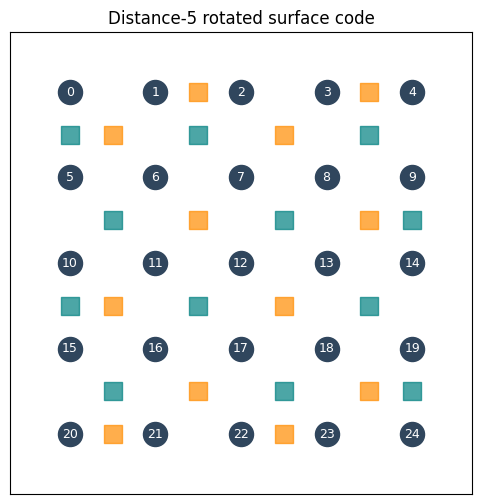

In [3]:
import numpy as np
import matplotlib.pyplot as plt
from qiskit_aer import AerSimulator
from qiskit_aer.noise import pauli_error
from qiskit_qec.circuits import SurfaceCodeCircuit
from qiskit_qec.decoders import UnionFindDecoder

DISTANCE = 5
layout = SurfaceCodeCircuit(d=DISTANCE, T=0, basis='z')
z_checks = [[q for q in p if q is not None] for p in layout.zplaqs]
x_checks = [[q for q in p if q is not None] for p in layout.xplaqs]
assert len(z_checks) == len(x_checks) == 12
print('Distance 5:', layout.n, 'data qubits,', len(z_checks), 'Z checks,', len(x_checks), 'X checks')

fig, ax = plt.subplots(figsize=(7, 6))
for q in range(layout.n):
    x, y = q % DISTANCE, q // DISTANCE
    ax.scatter(x, y, s=300, c='#30465d', zorder=3)
    ax.text(x, y, str(q), ha='center', va='center', color='white', fontsize=9, zorder=4)
for kind, checks, color in [('Z', z_checks, 'teal'), ('X', x_checks, 'darkorange')]:
    for check in checks:
        center = np.mean([[q % DISTANCE, q // DISTANCE] for q in check], axis=0)
        ax.scatter(*center, s=175, marker='s', color=color, alpha=0.7, zorder=2)
ax.set(xlim=(-0.7, 4.7), ylim=(4.7, -0.7), title='Distance-5 rotated surface code')
ax.set_xticks([]); ax.set_yticks([]); ax.set_aspect('equal')
plt.show()


### 2. Apply Pauli noise and collect shots

Our noise model applies **one independent Pauli channel to each data qubit, once per shot**:

- `I`: no error, with probability `1 - pX - pY - pZ`
- `X`, `Y`, or `Z`: Pauli errors, with probabilities `pX`, `pY`, and `pZ`

A *depolarizing* channel has equal X/Y/Z rates. A *biased* channel favors some Pauli errors over others. The reference implementation inserts this noise layer between two stabilizer-measurement rounds, then performs final data-qubit readout. **Gates, resets, and measurements are assumed ideal** in this simplified model.

The simulator knows which noise channel it applied, but the decoder must infer corrections from measured information, not from injected fault locations or logical-failure labels.

**Design distinction:** The provided `collect_shots()` is the **fixed reference experiment** and remains the experiment used in Stage 2. In Stage 1 you may implement a different circuit, code geometry, and number of syndrome rounds; keep **one noise application per data qubit per shot** and the same Stage 1 channel probabilities. Additional rounds do not add additional noise applications. Do not remove, bypass, or conditionally skip the prescribed noise layer.

In [4]:
TOTAL_P = 0.065
DEPOLARIZING = (TOTAL_P / 3,) * 3
KNOWN_BIAS = (0.002, 0.050, 0.013)   # Stage 1: X, Y, Z (sum = 0.065)
SHOTS_BASELINE = 5000                 # Introductory baseline per basis
SHOTS_LEARN = 30000                   # Stage 2: total Z-basis learning shots, across 10 trials
SHOTS_TEST = 10000                    # Stage 1: per basis; Stage 2: total per basis, across 10 trials
STAGE1_MAX_QUBITS = 49                  # Total simultaneously allocated physical qubits, including ancillas
STAGE1_MAX_MEASUREMENTS = 100           # Total single-qubit measurement operations per scored shot
STAGE2_TRIALS = 10
STAGE2_LEARN_PER_TRIAL = SHOTS_LEARN // STAGE2_TRIALS  # 3,000 Z-basis shots
STAGE2_TEST_PER_TRIAL = SHOTS_TEST // STAGE2_TRIALS   # 1,000 shots per basis
assert STAGE2_TRIALS * STAGE2_LEARN_PER_TRIAL == SHOTS_LEARN
assert STAGE2_TRIALS * STAGE2_TEST_PER_TRIAL == SHOTS_TEST

def collect_shots(basis, rates, shots, seed):
    """Qiskit QEC circuit, Aer Pauli errors, and raw Qiskit measurement strings."""
    px, py, pz = map(float, rates)
    if min(px, py, pz) < 0 or px + py + pz > 1:
        raise ValueError('Pauli probabilities must be nonnegative and sum to <= 1.')
    surface = SurfaceCodeCircuit(d=DISTANCE, T=0, basis=basis)
    surface.syndrome_measurement(final=False)
    channel = pauli_error([
        ('I', 1 - px - py - pz), ('X', px), ('Y', py), ('Z', pz)
    ]).to_instruction()
    for q in range(surface.n):
        surface.circuit['0'].append(channel, [surface.code_qubit[q]])
    surface.syndrome_measurement(final=True)
    surface.readout()
    simulator = AerSimulator(method='stabilizer')
    memory = simulator.run(surface.circuit['0'], shots=shots,
                           seed_simulator=seed, memory=True).result().get_memory()
    # Give the decoder a noise-free copy of the circuit. Qiskit QEC builds its
    # decoding graph by simulating faults in the circuit, and the Aer noise
    # channel above makes that simulation fail.
    decoder_surface = SurfaceCodeCircuit(d=DISTANCE, T=0, basis=basis)
    decoder_surface.syndrome_measurement(final=False)
    decoder_surface.syndrome_measurement(final=True)
    decoder_surface.readout()
    return decoder_surface, list(memory)

def failure_flags(surface, memory, decoder_class=UnionFindDecoder, **options):
    """One True/False result per shot: did UF leave a logical error?"""
    decoder = decoder_class(surface, **options)
    return np.array([
        any(int(value) != 0 for value in decoder.process(shot))
        for shot in memory
    ], dtype=bool)

def show_ler(name, fails):
    print(f'{name}: {fails.mean():.2%} LER over {len(fails):,} shots')


### 3. Establish the unmodified Union-Find reference baseline

First, observe the original `UnionFindDecoder` under **depolarizing noise**. This is a warm-up, **not** the scored Stage 1 model. The Stage 1 evaluation cell will separately measure the original UF decoder under the **known biased** channel.

For each basis,


$\mathrm{LER}_{b}=\frac{\text{number of logical failures in basis }b}{\text{number of scored shots in basis }b},\quad b\in\{X,Z\}.$


Report both basis-specific LERs and their equal-weight average. If you modify the Stage 1 circuit, your candidate and the fixed reference will generally produce **different measurement strings**; compare their LERs using the same physical noise model and equal shot budgets, rather than treating them as paired-shot decoding experiments.

In [5]:
baseline_by_basis = {}
for basis in ('z', 'x'):
    surface, memory = collect_shots(basis, DEPOLARIZING, SHOTS_BASELINE,
                                     seed=120 + (basis == 'x'))
    flags = failure_flags(surface, memory)
    baseline_by_basis[basis] = flags.mean()
    show_ler(f'Depolarizing / original UF / {basis}-basis', flags)
print('Mean LER across the two bases:',
      f'{np.mean(list(baseline_by_basis.values())):.2%}')


Depolarizing / original UF / z-basis: 2.70% LER over 5,000 shots
Depolarizing / original UF / x-basis: 2.04% LER over 5,000 shots
Mean LER across the two bases: 2.37%


### 4. Inspect a measured syndrome

A shot contains the final data-qubit readout and check outcomes from **both** stabilizer-measurement rounds. The next cell prints the checks whose outcomes **changed between rounds**; these changes do not reveal which Pauli error was injected.

Recall that **Z checks detect X-type error components** (X or Y), while **X checks detect Z-type components** (Z or Y). Correlations between the two types of checks are the key clue for distinguishing Y errors.

In [6]:
def changed_checks(shot):
    # Qiskit prints classical registers in reverse register order.
    # For the circuit above: data | X round 2 | Z round 2 | X round 1 | Z round 1
    parts = shot.split()
    if len(parts) != 5:
        raise ValueError(f'Expected 5 measurement groups, got {len(parts)}: {shot!r}')
    x_new = np.array([int(b) for b in parts[1][::-1]], dtype=np.int8)
    z_new = np.array([int(b) for b in parts[2][::-1]], dtype=np.int8)
    x_old = np.array([int(b) for b in parts[3][::-1]], dtype=np.int8)
    z_old = np.array([int(b) for b in parts[4][::-1]], dtype=np.int8)
    return z_new ^ z_old, x_new ^ x_old

example_surface, example_memory = collect_shots('z', KNOWN_BIAS, 30, 333)
example_index = next((i for i, s in enumerate(example_memory)
                      if any(np.concatenate(changed_checks(s)))), 0)
z_change, x_change = changed_checks(example_memory[example_index])
print('Z-check changes:', z_change.tolist())
print('X-check changes:', x_change.tolist())


Z-check changes: [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0]
X-check changes: [0, 0, 1, 0, 0, 0, 0, 0, 1, 0, 0, 1]


## Stage 1 — Known bias: co-design the code, circuit, and decoder

Every data qubit experiences the following **known** Pauli channel, applied **once per shot**:

| Error | `X` | `Y` | `Z` | `I` (no error) |
|---|---:|---:|---:|---:|
| Probability | `0.002` | `0.050` | `0.013` | `0.935` |

The total physical error probability is **0.065** per data qubit; Y errors dominate.

**Your task:** Improve logical reliability under this channel. You may modify the Union-Find decoding algorithm, **and you may redesign the encoded-qubit layout, syndrome circuit, and measurement schedule**. The distance-5 circuit above remains a useful working example, but is not required for your candidate. Your decoder should still be **Union-Find-based**; if you change codes, document how you construct the appropriate detection graph and apply UF to it.

### Stage 1 constraints

1. **Physical-qubit budget:** Use **at most 49 physical qubits simultaneously**, counting **all data qubits and ancillas**. You may trade data and ancilla qubits against each other. There is no separate requirement to use exactly 25 data qubits.
2. **Measurement budget:** Use **at most 100 individual qubit measurement operations per scored circuit shot**, including **intermediate syndrome/ancilla measurements and final data or logical readout**. Repeatedly measuring an ancilla counts each time. This is a per-shot measurement budget, **not** a limit of 100 simulator shots.
3. **Circuit and geometry freedom:** You may change stabilizer geometry, code asymmetry, state preparation, ancilla reuse, and the **number of stabilizer-measurement rounds**. You must encode **one logical qubit** and supply valid logical X and Z measurements. The example uses two rounds; **two rounds are not required** for Stage 1.
4. **Fixed physical noise:** Each data qubit receives the prescribed independent Pauli channel **exactly once per shot**, after logical state preparation and before final logical readout. Keep `pX = 0.002`, `pY = 0.050`, `pZ = 0.013`, with no additional fault information available to the decoder. As in the reference experiment, gates and measurement operations themselves are noiseless. Do not bypass the noise or replace it with a weaker channel.
5. **Decoder and integrity:** Retain **Union-Find as the core decoding approach**. Use only the published noise rates and observable measurement outcomes in choosing corrections. Do **not** use injected error locations, true logical outcomes, postselection, or trial-specific failure labels to decide a correction. Report all test shots, including failures.
6. **Evaluation:**  flexible total shot budget: Use exactly 20,000 scored test shots in total for your candidate, split between the logical X and Z bases however you choose. Both bases must receive shots. For example, you may use 6,000 X-basis shots and 14,000 Z-basis shots. Decide and document the allocation before evaluating your final candidate; do not change it based on favorable or unfavorable test outcomes. Compare against the original 5×5 reference circuit with unmodified UF, using the same number of shots in each basis and the same physical noise channel. The 20,000-shot budget applies to each evaluated circuit (candidate and reference separately). If you change the code or circuit, the raw shots are not paired; if you change only the decoder, you may process the same reference strings with both decoders.
7. **Required reporting:** For both logical bases and for both the reference and candidate, give the number of scored shots, number of logical failures, and LER (failures / shots). Also report the equal-weight mean (LER_X + LER_Z) / 2—do not pool all 20,000 shots into one shot-weighted LER, since the split is flexible. Include the candidate's actual physical-qubit and measurement counts, stabilizer-round count (if applicable), checks/logical operators, and a brief design explanation.

**Measurement-budget example:** The original 5×5 patch has 24 stabilizer checks. Measuring all checks twice plus 25 final data qubits uses `24×2 + 25 = 73` measurements; three check rounds would use `24×3 + 25 = 97`. Both fit under the 100-measurement cap.

**Hint 1 — Exploit correlated syndromes:** A Y error has both X and Z components and can flip **both types of stabilizer checks**. Could correlations across check types help Union-Find choose between otherwise plausible corrections?

**Hint 2 — Change the geometry:** Does a square patch make sense under asymmetric noise? For example, consider a **rectangular layout, perhaps 3×8 data qubits**, with boundary orientation chosen to give **greater distance against Z-type logical errors**. What protection do you lose in the other basis, and does the tradeoff improve the **average** LER? The supplied `SurfaceCodeCircuit(d=...)` builds square patches, so a rectangular code requires your own valid stabilizers, logical operators, and measurement circuit.

In [ ]:
class BiasAwareUnionFind(UnionFindDecoder):
    def __init__(self, code, probabilities):
        super().__init__(code)
        self.probabilities = probabilities

    def process(self, shot, predecoder=None):
        # TODO: bias-aware modifications to UF using the published noise rates.
        # For a custom code/layout, you may need a different UF graph adapter
        # instead of subclassing this square-patch implementation.
        # Until you implement this, it behaves like original UF.
        return super().process(shot, predecoder=predecoder)

### Stage 1 checkpoint — evaluate your design against the reference

The fixed **reference** is the original 5×5, two-round circuit decoded by unmodified UF. Your **candidate** can use another code, circuit, and/or UF-based decoder within the Stage 1 limits.

The next cells provide a **working starter candidate**: the same reference circuit with `BiasAwareUnionFind`. To change the circuit or geometry, **leave the reference `collect_shots()` function unchanged** and replace `stage1_candidate_failure_flags()` with your own simulation and decoder. Return one logical-failure flag per test shot and an accurate resource report for your circuit. The Stage 1 scorer will continue to evaluate the fixed reference separately.

**Important:** A circuit redesign will usually produce different shot strings from the reference. Do not feed different circuit formats into the same `UnionFindDecoder` or claim the results are paired-shot. Your comparison is **LER under the same noise channel and test-shot budget**. Paired-shot comparisons remain appropriate for comparing two decoders on the *same* circuit (as in Stage 2).

In [ ]:
def stage1_resource_report(circuit):
    """Validate a scored Stage 1 Qiskit circuit against shared resource limits.

    Count each QuantumCircuit measurement instruction as one outcome,
    whether it is a syndrome measurement or a final readout.
    """
    physical_qubits = circuit.num_qubits
    measurements = sum(inst.operation.name == 'measure' for inst in circuit.data)
    if physical_qubits > STAGE1_MAX_QUBITS:
        raise ValueError(f'Stage 1 uses {physical_qubits} physical qubits; max is {STAGE1_MAX_QUBITS}.')
    if measurements > STAGE1_MAX_MEASUREMENTS:
        raise ValueError(f'Stage 1 uses {measurements} measurement operations; '
                         f'max is {STAGE1_MAX_MEASUREMENTS}.')
    return {'physical_qubits': physical_qubits, 'measurements_per_shot': measurements}


def stage1_candidate_failure_flags(basis, shots, seed):
    """Starter Stage 1 candidate: original circuit + your UF subclass.

    TODO IF REDESIGNING THE CIRCUIT: build a valid code and its Z- and X-basis
    experiments; insert the prescribed Pauli channel ONCE per data qubit;
    simulate exactly `shots` trials; decode them with UF; and return
    (boolean failure flags, resource report). The supplied
    SurfaceCodeCircuit helper only builds square patches.

    Code and logical-measurement correctness are participant responsibilities.
    This helper validates counts, not stabilizer correctness or noise placement.
    """
    surface, memory = collect_shots(basis, KNOWN_BIAS, shots, seed)
    resources = stage1_resource_report(surface.circuit['0'])
    decoder = BiasAwareUnionFind(surface, probabilities=KNOWN_BIAS)
    fails = np.array([
        any(int(v) != 0 for v in decoder.process(shot)) for shot in memory
    ], dtype=bool)
    return fails, resources


In [ ]:
# Scored Stage 1 results: original 5x5 UF reference vs your resource-limited candidate.
# A redesigned circuit need not produce the same measurement strings as the reference.
stage1_results = {}
stage1_resources = {}
for basis in ('z', 'x'):
    seed = 502 + (basis == 'x')
    reference_surface, reference_memory = collect_shots(
        basis, KNOWN_BIAS, SHOTS_TEST, seed=seed)
    reference_failures = failure_flags(reference_surface, reference_memory)
    candidate_failures, resources = stage1_candidate_failure_flags(
        basis, SHOTS_TEST, seed=seed)
    candidate_failures = np.asarray(candidate_failures, dtype=bool)
    if candidate_failures.shape != (SHOTS_TEST,):
        raise ValueError(f'Stage 1 candidate must return {SHOTS_TEST} failure flags per basis.')
    if (resources['physical_qubits'] > STAGE1_MAX_QUBITS or
            resources['measurements_per_shot'] > STAGE1_MAX_MEASUREMENTS):
        raise ValueError('Stage 1 candidate exceeds the physical-resource limits.')
    stage1_results[basis] = (float(reference_failures.mean()),
                             float(candidate_failures.mean()))
    stage1_resources[basis] = resources
    print(f'{basis.upper()} basis / {SHOTS_TEST:,} shots: '
          f'5x5 UF reference {reference_failures.mean():.2%} '
          f'({reference_failures.sum()} fails) | '
          f'candidate {candidate_failures.mean():.2%} '
          f'({candidate_failures.sum()} fails) | '
          f'{resources["physical_qubits"]} qubits, '
          f'{resources["measurements_per_shot"]} measurements/shot')

print('Equal-weight mean Stage 1 LER: '
      f'UF reference {np.mean([v[0] for v in stage1_results.values()]):.2%} | '
      f'candidate {np.mean([v[1] for v in stage1_results.values()]):.2%}')

## Stage 2 — Unknown bias: ten independent trials

In Stage 2, the **total probability of a Pauli error is always 0.065**, but the breakdown among X, Y, and Z errors changes from trial to trial. For each trial, the simulator first samples a single probability vector:


$(w_X,w_Y,w_Z) \sim \mathrm{Dirichlet}(1.5,5.5,1.5),
\qquad (p_X,p_Y,p_Z)=0.065(w_X,w_Y,w_Z).$

The resulting probabilities are **fixed throughout that trial**, including its learning shots and both test bases. The next trial gets a fresh independently sampled vector. The distribution itself is public, but **the sampled probabilities are not decoder inputs**.

**Your task:** In each of the **10 trials**, estimate `(pX, pY, pZ)` from the trial's Z-basis learning measurements. Pass **only your estimates** to a Union-Find-based decoder that works with the **fixed 5×5 reference circuit**, and compare against unmodified UF on the same held-out strings. You may reuse your Stage 1 decoder ideas, but **Stage 2 does not permit Stage 1 geometry/circuit redesigns**. If you designed a custom code in Stage 1, provide a 5×5-compatible UF adaptation here.

### Stage 2 constraints

1. **Fixed hardware and noise family:** Use the **fixed reference** distance-5 code (25 data qubits), check ancillas, two stabilizer rounds, and independent Pauli channel. Keep `pX + pY + pZ = 0.065`; do not change the simulation or decoding circuit to improve results.
2. **Ten trials, no selection:** Run **exactly 10 trials** from the prescribed Dirichlet distribution using the supplied seeds. Report **all ten**, not just favorable results. Do not redraw, drop, or repeat trials to improve your score.
3. **Learning budget:** For **each trial**, use exactly **3,000 Z-basis learning shots**. No X-basis training shots or extra calibration simulations. This totals 30,000 learning shots across all trials.
4. **Held-out test budget:** For **each trial**, use exactly **1,000 Z-basis and 1,000 X-basis test shots**, separate from the learning data. Across all trials that is 10,000 test shots per basis. Both decoders must evaluate **the same test measurement strings**.
5. **Strict separation of simulator and decoder:** The sampled raw `(pX, pY, pZ)` may be used **only to configure the simulator's noise channel**. It must **never** be passed to your estimator, decoder, calibration routine, or analysis code. Do not reconstruct it from the simulator's random seed, inspect injected error locations, or use test labels to fit your estimator. The decoder may use only measured syndromes, the publicly known total `0.065`, and your estimated probabilities from learning data.
6. **Estimator and decoder:** Keep Union-Find as the core decoding algorithm. Implement `estimate_pauli_probabilities(shots, surface)` to return **three finite, nonnegative estimates** in X/Y/Z order, normalized to sum to `0.065`. Apply your **5×5-compatible UF-based decoder** using those estimates, not the raw simulator probabilities.
7. **Output-based grading:** Provide one result row for **each of the ten trials**, including its estimated `(pX, pY, pZ)` and the original-versus-modified UF LER in **both** logical bases. Also report the **ten-trial mean** LER for each basis and the equal-weight average over X and Z. Your output and explanation are what the organizers will grade; submitted code should document how you produced them.

**Hints:** Z-check changes respond to X/Y errors, while X-check changes respond to Z/Y errors. Joint patterns across nearby X and Z checks may help distinguish Y from the other errors.


In [ ]:
# A trial's raw probabilities exist only *inside* this simulator helper.
# They are deliberately not returned, logged, or passed to the estimator/decoder.
# Fixed, distinct seeds make the ten randomized trials reproducible for reporting.
def unknown_noise_experiment(trial_index):
    if not 0 <= trial_index < STAGE2_TRIALS:
        raise ValueError(f"trial_index must be 0..{STAGE2_TRIALS - 1}")

    rng = np.random.default_rng(20261103 + trial_index)
    simulator_only_rates = rng.dirichlet([1.5, 5.5, 1.5]) * TOTAL_P

    train_surface, learning_shots = collect_shots(
        'z', simulator_only_rates, STAGE2_LEARN_PER_TRIAL,
        seed=40000 + 10 * trial_index)
    test_data = {}
    for basis in ('z', 'x'):
        test_data[basis] = collect_shots(
            basis, simulator_only_rates, STAGE2_TEST_PER_TRIAL,
            seed=50000 + 10 * trial_index + (basis == 'x'))
    return train_surface, learning_shots, test_data

print(f'Stage 2: {STAGE2_TRIALS} trials, total p = {TOTAL_P:.3f}')
print(f'Per trial: {STAGE2_LEARN_PER_TRIAL:,} learning shots (Z), '
      f'{STAGE2_TEST_PER_TRIAL:,} held-out shots per basis')
print('The generator returns measurements, not the hidden simulator probabilities.')


In [ ]:
def estimate_pauli_probabilities(shots, surface):
    # TODO: infer (pX, pY, pZ) using ONLY these Z-basis learning shots,
    # the circuit structure, and the known total probability TOTAL_P = 0.065.
    # Return three finite, nonnegative values summing to TOTAL_P.
    # NEVER read, reconstruct, or pass through the simulator's raw rates.
    raise NotImplementedError('Estimate the X/Y/Z probabilities from shots.')


In [ ]:
# Stage 2: compare two UF decoders on identical held-out strings.
def compare_on_same_shots(surface, memory, probabilities):
    original = UnionFindDecoder(surface)
    adapted = BiasAwareUnionFind(surface, probabilities=probabilities)
    original_fails = np.array([any(int(v) != 0 for v in original.process(s)) for s in memory], bool)
    adapted_fails = np.array([any(int(v) != 0 for v in adapted.process(s)) for s in memory], bool)
    return original_fails, adapted_fails


### Stage 2 checkpoint — evaluate all ten trials

After completing `estimate_pauli_probabilities`, uncomment the final line of the evaluation cell. The helper will run the **ten prescribed noise realizations** and print a trial-by-trial results table plus the aggregate means.

The **true** X/Y/Z probabilities are used inside `unknown_noise_experiment()` **only** to generate measurements. Your estimator receives just the 3,000 Z-basis training strings and their circuit; your decoder receives only the **estimated** probabilities and each held-out test string.

For fair, output-only grading, include the **complete table of ten trials** in your PDF, even when a trial makes your decoder worse than original UF. The two decoders are evaluated on **identical held-out test shots** within each basis and trial.


In [ ]:
def evaluate_stage2():
    """Run all 10 trials, keeping hidden simulator rates away from the decoder."""
    trial_rows = []
    print('Trial | est pX   est pY   est pZ  | Z: UF / modified | X: UF / modified')
    print('-' * 79)
    for trial_index in range(STAGE2_TRIALS):
        train_surface, learning_shots, test_data = unknown_noise_experiment(trial_index)
        estimate = np.asarray(
            estimate_pauli_probabilities(learning_shots, train_surface), dtype=float
        )
        if estimate.shape != (3,) or not np.all(np.isfinite(estimate)):
            raise ValueError('Estimator must return three finite probabilities: (pX, pY, pZ).')
        if np.any(estimate < 0) or not np.isclose(estimate.sum(), TOTAL_P, atol=1e-6):
            raise ValueError(f'Estimated rates must be >=0 and sum to {TOTAL_P}; got {estimate}.')
        row = {'trial': trial_index + 1, 'estimates': estimate.tolist()}
        for basis in ('z', 'x'):
            surface, memory = test_data[basis]
            original_fails, adapted_fails = compare_on_same_shots(surface, memory, estimate)
            row[basis] = (float(original_fails.mean()), float(adapted_fails.mean()))
        trial_rows.append(row)
        print(f"{row['trial']:>5} | {estimate[0]:.4f}   {estimate[1]:.4f}   "
              f"{estimate[2]:.4f} | {row['z'][0]:.2%} / {row['z'][1]:.2%}"
              f"     | {row['x'][0]:.2%} / {row['x'][1]:.2%}")

    summary = {
        basis: (
            float(np.mean([r[basis][0] for r in trial_rows])),
            float(np.mean([r[basis][1] for r in trial_rows])),
        ) for basis in ('z', 'x')
    }
    original_avg = float(np.mean([summary['z'][0], summary['x'][0]]))
    modified_avg = float(np.mean([summary['z'][1], summary['x'][1]]))
    print('-' * 79)
    print(f"10-trial mean Z LER: UF {summary['z'][0]:.2%} | modified {summary['z'][1]:.2%}")
    print(f"10-trial mean X LER: UF {summary['x'][0]:.2%} | modified {summary['x'][1]:.2%}")
    print(f"Equal-weight mean:   UF {original_avg:.2%} | modified {modified_avg:.2%}")
    return trial_rows, summary

# Uncomment after implementing the estimator; then include the FULL output in your PDF.
# stage2_trial_results, stage2_results = evaluate_stage2()


## Results and submission checklist

Plot **original UF reference versus your candidate** for both logical bases in Stage 1, and **original versus modified UF on identical held-out strings** for Stage 2. Explain both the advantages and any tradeoffs.

Your write-up should include:

- **Stage 1 design:** Describe the code/circuit geometry, number of data and ancillary qubits, stabilizer checks, logical X and Z observables, number of syndrome rounds (if applicable), and UF decoder/graph modification.
- **Stage 1 resource accounting:** State **physical qubits (max 49)**, **measurement operations per shot (max 100)**, and **10,000 scored shots in each logical basis**. Count both intermediate and final measurements, and include measurement/reset reuse in your method description.
- **Stage 1 results:** Report reference and candidate **failure counts and LERs in both bases**, and their equal-weight mean. For redesigned circuits, acknowledge that the reference and candidate use **different shot strings** under the **same error channel**, not a paired decoder comparison.
- **Stage 2 method:** Describe how you estimate unknown bias using **measurement data only**, and how those estimates change your **5×5-compatible** UF decoder. Stage 2 uses the fixed reference code and circuit.
- **Stage 2 results:** Include **all 10 randomized trials**, each with estimated `(pX, pY, pZ)` and original-versus-modified LER in Z and X. Report the **ten-trial means** and the **equal-weight average** of the two logical bases.
- **Integrity:** Confirm that simulator-only bias parameters never enter the Stage 2 estimator/decoder, and that no injected-error labels, logical-failure labels, postselection, or favorable-trial selection were used.
- **Interpretation:** Where did the method help or hurt, and why do the logical X and Z bases behave differently?

**How results are judged:** Organizers will inspect reported outputs, code, resource accounting, and explanations rather than execute every notebook in a common environment. **Note that partial submissions including work on only one of the stage one WILL be scored.** For example, if you are spend all of your time on stage 1 to deliver an extremely strong solution, your placement will account for your extra efforts.

**Deliverable:** A ZIP with (1) a completed `.ipynb` showing code/output, (2) a PDF with methods, tables, plots, and summary LERs, and (3) any imported `.py` helpers. Do not include generated datasets unless requested.

In [ ]:
results_to_plot = [('Stage 1 / ' + b, *v) for b, v in stage1_results.items()]
if 'stage2_results' in globals():
    results_to_plot += [('Stage 2 / ' + b, *v) for b, v in stage2_results.items()]
labels = [r[0] for r in results_to_plot]
original = [100 * r[1] for r in results_to_plot]
changed = [100 * r[2] for r in results_to_plot]
xx = np.arange(len(labels))
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.bar(xx - 0.18, original, width=0.36, label='Original UF')
ax.bar(xx + 0.18, changed, width=0.36, label='Modified UF')
ax.set_xticks(xx, labels, rotation=20, ha='right')
ax.set_ylabel('Logical error rate (%)')
ax.legend()
plt.tight_layout(); plt.show()


## What this model does—and does not—simulate

This is a deliberately controlled **code-capacity-style** model: each data qubit experiences **one independent Pauli channel per shot**, while **gate errors and measurement errors are omitted**. The per-data-qubit error probability is fixed at `0.065`.

- **Stage 1** permits code- and circuit-level co-design, including rectangular/asymmetric patches and freely chosen syndrome rounds, but caps **49 physical qubits** and **100 individual measurement operations per scored shot**. The prescribed noise layer must still act once on each data qubit.
- **Stage 2** uses the original **25-data-qubit, distance-5, two-round reference circuit** for every trial. Its ten simulator-only X/Y/Z probability vectors are independently sampled but always sum to `0.065`; only measurement data and estimated bias may be used by the decoder.

**Physics note:** Under this ideal measurement model, repeating the **same** stabilizer checks without an intervening additional error event may not add information. More syndrome rounds are permitted in Stage 1, but are not automatically better—and every measurement counts against the 100-measurement budget.

The supplied `SurfaceCodeCircuit` and `UnionFindDecoder` come from the archived **Qiskit QEC** research package. `SurfaceCodeCircuit(d=...)` implements a square patch; a redesigned geometry needs its own stabilizer/circuit implementation and a Union-Find decoding graph.